### Dependencies

In [1]:
# Import dependencies
import cv2
import os
import random
import numpy as np
from matplotlib import pyplot as plt

In [2]:
 # Import Tensor flow dependencies - Functional API
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer, Conv2D, Dense, MaxPooling2D, Input, Flatten
import tensorflow as tf

I0000 00:00:1781121291.554855    4518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781121291.561383    4518 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1781121292.211095    4518 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781121297.311667    4518 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

### Folder Structure

In [3]:
# Setup paths
POS_PATH = os.path.join('data','positive')
NEG_PATH = os.path.join('data','negative')
ANC_PATH = os.path.join('data','anchor')

In [4]:
# Import uuid to generate unique image names (universally unique identifiers)
import uuid

### Loading the training dataset

In [5]:
# Getting the images from their directories
anchor = tf.data.Dataset.list_files(ANC_PATH+'/*.jpg').take(2000)
positive = tf.data.Dataset.list_files(POS_PATH+'/*.jpg').take(2000)
negative = tf.data.Dataset.list_files(NEG_PATH+'/*.jpg').take(2000)

E0000 00:00:1781121303.718515    4518 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Preprocessing the images

In [6]:
def preprocess(file_path):
    # Read and decode image
    byte_img = tf.io.read_file(file_path)
    img = tf.io.decode_jpeg(byte_img)
    
    # Resize to 100x100
    img = tf.image.resize(img, (100,100))
    
    # Scale to [0, 1]
    img = img / 255.0
    
    return img

In [7]:
img = preprocess('data/anchor/4f950650-e0e2-11f0-9f86-d3af34889cdd.jpg')

In [8]:
img.numpy().max()

0.9941176

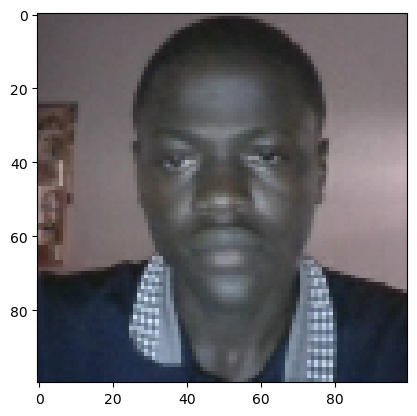

In [9]:
plt.imshow(img)

In [10]:
# Creating a labelled dataset
positives = tf.data.Dataset.zip((anchor, positive, tf.data.Dataset.from_tensor_slices(tf.ones(len(anchor)))))
negatives = tf.data.Dataset.zip((anchor, negative, tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
data = positives.concatenate(negatives)

In [11]:
# When the resulting number is 0 = mismatch, 1 = match

samples = data.as_numpy_iterator()
example = samples.next()

In [12]:
# Build, train and test partition
def preprocess_twin(input_img, validation_img, label):
    return(preprocess(input_img), preprocess(validation_img), label)

In [13]:
# The * is unpacking the image value inside of the tupple
res = preprocess_twin(*example)

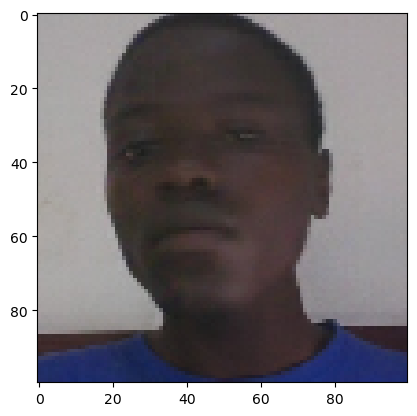

In [14]:
plt.imshow(res[0])

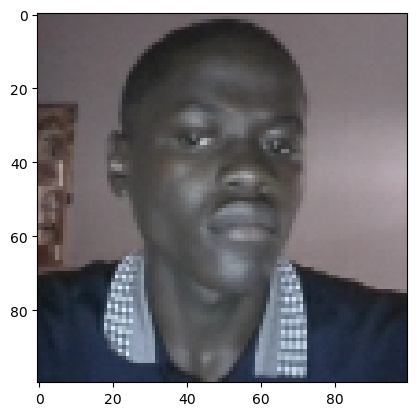

In [15]:
plt.imshow(res[1])

In [16]:
res[2]

1.0

### Data Loader Pipeline

In [17]:
# Build Dataloader pipeline
data = data.map(preprocess_twin)
data = data.cache()
data = data.shuffle(buffer_size = 10000)

In [18]:
# Training partition
train_data = data.take(round(len(data)*.7))
train_data = train_data.batch(16)
train_data = train_data.prefetch(8)

In [19]:
# Testing partition
test_data = data.skip(round(len(data)*.7))
test_data = test_data.take(round(len(data)*.3))
test_data = test_data.batch(16)
test_data = test_data.prefetch(8)

### Building the embedding function

In [20]:
def make_embedding(): 
    input_image = Input(shape=(100,100,3), name='input_image')
    
    # First block
    c1 = Conv2D(64, (10,10), activation='relu')(input_image)
    m1 = MaxPooling2D(64, (2,2), padding='same')(c1)
    
    # Second block
    c2 = Conv2D(128, (7,7), activation='relu')(m1)
    m2 = MaxPooling2D(64, (2,2), padding='same')(c2)
    
    # Third block 
    c3 = Conv2D(128, (4,4), activation='relu')(m2)
    m3 = MaxPooling2D(64, (2,2), padding='same')(c3)
    
    # Final embedding block
    c4 = Conv2D(256, (4,4), activation='relu')(m3)
    f1 = Flatten()(c4)
    d1 = Dense(4096, activation=None)(f1)
    
    return Model(inputs=[input_image], outputs=[d1], name='embedding')

In [21]:
embedding = make_embedding()

In [22]:
embedding.summary()

Model: "embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 91, 91, 64)     │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 46, 46, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 40, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 17, 17, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    37,752,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,960,448 (148.62 MB)

 Trainable params: 38,960,448 (148.62 MB)

 Non-trainable params: 0 (0.00 B)

### Database(embedding of known faces)

In [23]:
TEST_PATH = os.path.join('application_data', 'verification_images')
lookup_table = {}

for image_name in os.listdir(TEST_PATH):
    if image_name.endswith(('.jpg', '.jpeg', '.png')):
        img_path = os.path.join(TEST_PATH, image_name)
        
        # Preprocess
        processed_img = preprocess(img_path)
        
        # Add batch dimension
        input_data = np.expand_dims(processed_img, axis=0)
        
        # Generate Embedding and flatten to 1D
        # predict() returns (1, N), we want just (N,)
        img_embedding = embedding.predict(input_data).flatten()
        
        # Strip extension to get 'matricule'
        # Example: '12345.jpg' -> '12345'
        matricule = os.path.splitext(image_name)[0]
        
        # Save to lookup table
        lookup_table[matricule] = img_embedding

# Store in a compressed .npz file
# The ** operator unpacks the dictionary into named arguments for the file
np.savez_compressed('database_embeddings.npz', **lookup_table)

print(f"Stored {len(lookup_table)} embeddings in 'database_embeddings.npz'.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
Stored 2 embeddings in 'database_embeddings.npz'.


In [24]:
# Load the database
db = np.load('database_embeddings.npz')
db

NpzFile 'database_embeddings.npz' with keys: Adrien_Brody_0008, CT23A004

In [25]:
# Access a specific matricule
target_id = 'CT23A004'
if target_id in db:
    print(f"Embedding for {target_id}: {db[target_id]}")

Embedding for CT23A004: [-0.02659424 -0.13570854  0.07484249 ...  0.0044677  -0.01559998
 -0.05227275]


In [26]:
(db[target_id]).shape

(4096,)

In [27]:
# Access every matricule embedding pair
for target in db:
    print(f'Embedding {target}: {db[target]}')

Embedding Adrien_Brody_0008: [-0.0530679  -0.12094479  0.07786483 ...  0.01887758  0.0115266
 -0.06486458]
Embedding CT23A004: [-0.02659424 -0.13570854  0.07484249 ...  0.0044677  -0.01559998
 -0.05227275]


In [28]:
# Create a TFLite version of JUST the embedding part for the app
converter = tf.lite.TFLiteConverter.from_keras_model(embedding)
tflite_model = converter.convert()
with open('embedding_model.tflite', 'wb') as f:
    f.write(tflite_model)

INFO:tensorflow:Assets written to: /tmp/tmp29rxn90u/assets


INFO:tensorflow:Assets written to: /tmp/tmp29rxn90u/assets


Saved artifact at '/tmp/tmp29rxn90u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 100, 100, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 4096), dtype=tf.float32, name=None)
Captures:
  123622163669712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163669520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163670864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163672400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163672016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163670096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163673552: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1781121321.593305    4518 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1781121321.593511    4518 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1781121321.598662    4518 reader.cc:83] Reading SavedModel from: /tmp/tmp29rxn90u
I0000 00:00:1781121321.599811    4518 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1781121321.599838    4518 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp29rxn90u
I0000 00:00:1781121321.615369    4518 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1781121321.617885    4518 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1781121322.552975    4518 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp29rxn90u
I0000 00:00:1781121322.593030    4518 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 994404 microseconds.
I0000 00:00:1781121322.693608    451

### Siamese L1 Distance class

In [29]:
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
       
    def call(self, inputs):
        # We grab the 0th element of the 0th element, and 0th of the 1st.
        # This strips away the double-nesting: [[tensor1], [tensor2]] -> tensor1, tensor2
        input_embedding = inputs[0][0]
        validation_embedding = inputs[1][0]
        
        return tf.math.abs(input_embedding - validation_embedding)

In [30]:
l1 = L1Dist()

### Building the Siamese Model

In [31]:
 def make_siamese_model():

     # Handle inputs
     input_image = Input(name = 'input_img', shape = (100,100,3))

     # Validation image in the network
     validation_image = Input(name = 'validation_img', shape = (100,100,3))

     # Combine siamese distance compon ents
     siamese_layer = L1Dist()
     siamese_layer._name = 'distance'
     distances = siamese_layer([embedding(input_image), embedding(validation_image)])

     # Classification layer
     classifier = Dense(1, activation = 'sigmoid')(distances)

     return Model(inputs = [input_image, validation_image], outputs = classifier, name = 'SiameseNetwork')

In [32]:
siamese_model = make_siamese_model()

In [33]:
siamese_model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist_1 (L1Dist)  │ (None, 4096)      │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │      4,097 │ l1_dist_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)

### Training the Siamese model

In [34]:
# Setup loss and optimizer
binary_cross_loss = tf.losses.BinaryCrossentropy()

In [35]:
# Defining optimizer
opt = tf.keras.optimizers.Adam(1e-4)

In [36]:
# Establishing checkpoints
checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, 'ckpt')
checkpoint = tf.train.Checkpoint(opt = opt, siamese_model = siamese_model)

In [37]:
# Building the train step function
@tf.function
def train_step(batch):

    with tf.GradientTape() as tape:
        # Get anchor and postive/negative image
        x = batch[:2]
        # Get label
        y = batch[2]

        # Forward pass
        yhat = siamese_model(x, training = True)
        
        # Calculate loss
        loss = binary_cross_loss(y, yhat)
        
    # Calculating gradients
    grad = tape.gradient(loss, siamese_model.trainable_variables)

    # Calculate updated weights and apply to siames model
    opt.apply_gradients(zip(grad, siamese_model.trainable_variables))

    # Returning loss
    return loss

In [38]:
# Import Evaluation Metrics
from tensorflow.keras.metrics import Precision, Recall

In [39]:
# Building the training loop

def train(data, EPOCHS):
    # Loop through epochs
    for epoch in range(1, EPOCHS+1):
        print('\n Epoch {}/{}'.format(epoch, EPOCHS))
        progbar = tf.keras.utils.Progbar(len(data))

        # Creating a metric object
        r = Recall()
        p = Precision()

        # Loop through each batch
        for idx, batch in enumerate(data):
            # Running the train step
            loss = train_step(batch)
            yhat = siamese_model.predict(batch[:2])
            r.update_state(batch[2], yhat)
            p.update_state(batch[2], yhat)
            progbar.update(idx+1)

        print(loss.numpy(), r.result().numpy(), p.result().numpy())

        # Save Checkpoint
        if epoch % 10 == 0:
            checkpoint.save(file_prefix = checkpoint_prefix)

In [40]:
# Training the Model
EPOCHS = 50

In [41]:
train(train_data, EPOCHS)


 Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 816ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 704ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 650ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 605ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 608ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 629ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 642ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 643ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 607ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 620ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 645ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 610ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 640ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 633ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 629ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 785ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 807ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 797ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 816ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 911ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 802ms/step
1/1 ━━━━━━━━

In [42]:
# Get a batch of test data
test_input, test_val, y_true = test_data.as_numpy_iterator().next()

In [43]:
y_hat = siamese_model.predict([test_input, test_val])
y_hat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step


array([[1.2226072e-29],
       [1.0000000e+00],
       [9.2580195e-31],
       [4.6327890e-27],
       [1.9989755e-30],
       [1.0000000e+00],
       [5.0602874e-35],
       [2.8190202e-36],
       [8.3433928e-18],
       [1.0000000e+00],
       [7.6227571e-14],
       [3.5524070e-20],
       [8.2788795e-17],
       [1.0000000e+00],
       [1.0000000e+00],
       [1.4012809e-16]], dtype=float32)

In [44]:
# Post processing the results
[1 if prediction > 0.5 else 0 for prediction in y_hat]

[0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0]

In [45]:
y_true

array([0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0.],
      dtype=float32)

### Visualising the Results

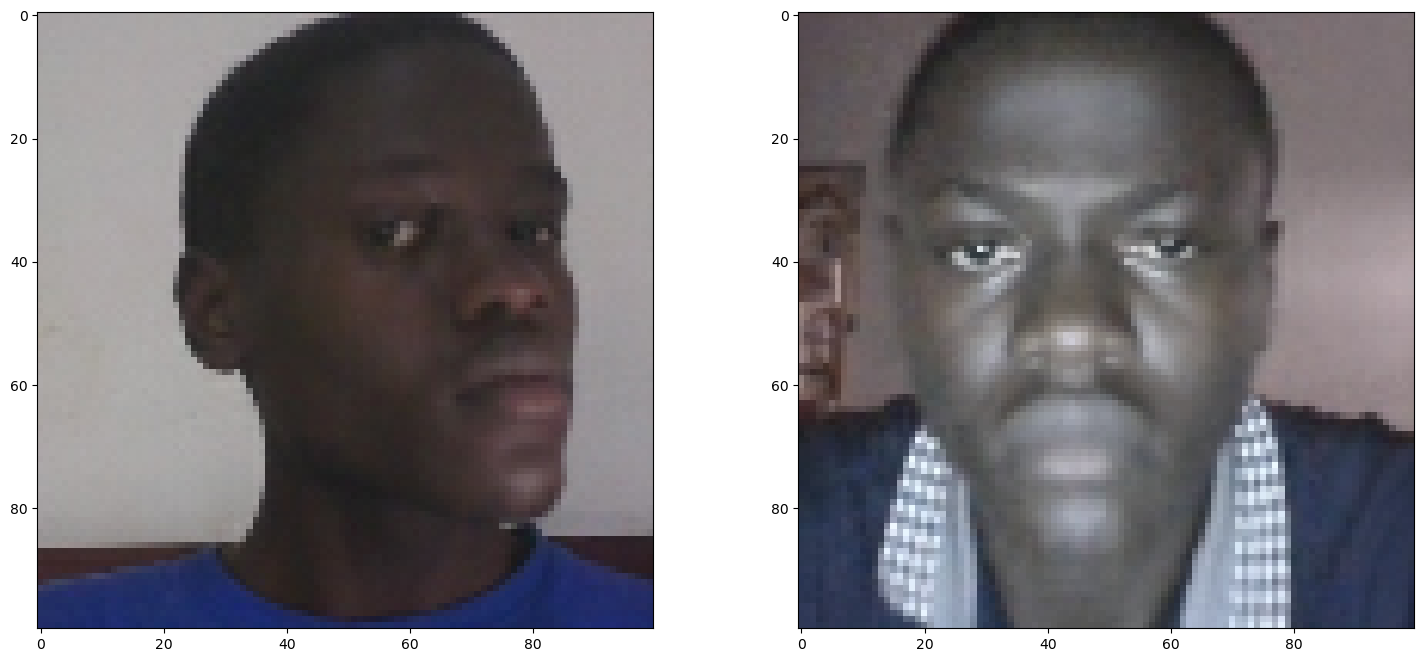

In [47]:
# Set plot size
plt.figure(figsize = (18,8)) 

# Set first subplot
plt.subplot(1,2,1)
plt.imshow(test_input[1])

# Set second subplot
plt.subplot(1,2,2)
plt.imshow(test_val[1])

# Rendering the clean output
plt.show()

### Saving the Model for Deployment

In [48]:
# Save weights

siamese_model.save('verifyme.keras')

In [49]:
# Converting to TFLite for app deployment
converter = tf.lite.TFLiteConverter.from_keras_model(siamese_model)
tflite_model = converter.convert()

with open('./siamese_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("Model saved and converted for deployment.")

INFO:tensorflow:Assets written to: /tmp/tmpd2mju8y6/assets


INFO:tensorflow:Assets written to: /tmp/tmpd2mju8y6/assets


Saved artifact at '/tmp/tmpd2mju8y6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 100, 100, 3), dtype=tf.float32, name='input_img'), TensorSpec(shape=(None, 100, 100, 3), dtype=tf.float32, name='validation_img')]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  123622163669712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163669520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163670864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163672400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163671632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163672016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  123622163670096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

W0000 00:00:1781125950.112784    4518 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1781125950.113086    4518 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1781125950.118460    4518 reader.cc:83] Reading SavedModel from: /tmp/tmpd2mju8y6
I0000 00:00:1781125950.119188    4518 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1781125950.119214    4518 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpd2mju8y6
I0000 00:00:1781125950.137988    4518 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1781125950.671608    4518 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpd2mju8y6
I0000 00:00:1781125950.679990    4518 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 561538 microseconds.


Model saved and converted for deployment.


### Reloading the Model

In [50]:
# Siamese L1 Distance class
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
       
    def call(self, inputs):
        # We grab the 0th element of the 0th element, and 0th of the 1st.
        # This strips away the double-nesting: [[tensor1], [tensor2]] -> tensor1, tensor2
        input_embedding = inputs[0][0]
        validation_embedding = inputs[1][0]
        
        return tf.math.abs(input_embedding - validation_embedding)

In [51]:
l1 = L1Dist()

In [52]:
# Get a batch of test data
test_input, test_val, y_true = test_data.as_numpy_iterator().next()

In [53]:
# Get a batch of test data
test_input, test_val, y_true = test_data.as_numpy_iterator().next()

In [ ]:
model = tf.keras.models.load_model('verifyme.keras', custom_objects={'L1Dist': L1Dist, 'BinaryCrossentropy': tf.losses.BinaryCrossentropy})

In [54]:
model.predict([test_input, test_val])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step


array([[2.8136447e-31],
       [0.0000000e+00],
       [1.0000000e+00],
       [1.0000000e+00],
       [9.9997252e-01],
       [9.9252594e-01],
       [1.0000000e+00],
       [1.2449740e-26],
       [0.0000000e+00],
       [1.8373368e-25],
       [1.0494395e-30],
       [0.0000000e+00],
       [9.9999934e-01],
       [3.5199650e-20],
       [0.0000000e+00],
       [0.0000000e+00]], dtype=float32)

In [55]:
# View Model summary
model.summary()

Model: "SiameseNetwork"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_img           │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ validation_img      │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 4096)      │ 38,960,448 │ input_img[0][0],  │
│ (Functional)        │                   │            │ validation_img[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ l1_dist_1 (L1Dist)  │ (None, 4096)      │          0 │ embedding[0][0],  │
│                     │                   │            │ embedding[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │      4,097 │ l1_dist_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,964,545 (148.64 MB)

 Trainable params: 38,964,545 (148.64 MB)

 Non-trainable params: 0 (0.00 B)